# Classificació C vs IP (FCz i Oz, 1000-1500 ms)

## Passos del notebook

1. Executar la inicialització compartida (imports, rutes, constants i funcions base).
2. Construir característiques espectrals amb la configuració acordada: FCz theta (5-7 Hz) i Oz alpha (8-12 Hz), finestra 1000-1500 ms.
3. Preparar les etiquetes de classificació C vs I amb mapatge homogeni entre notebooks.
4. Aplicar el protocol de balanceig acordat (a nivell d'individu) només en les particions d'entrenament.
5. Entrenar models per subjecte i calcular mètriques comparables (accuracy, F1 macro i resum agregat).
6. Presentar els resultats finals amb format coherent i traçable respecte del notebook d'exploració.

In [ ]:
import nbformat
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import norm

try:
    from google.colab import drive

    IN_COLAB = True
    drive.mount("/content/drive")
except ImportError:
    drive = None
    IN_COLAB = False

from imblearn.under_sampling import RandomUnderSampler
from lightgbm import LGBMClassifier
from scipy.stats import chi2
from sklearn.decomposition import PCA, FastICA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

if IN_COLAB:
    DRIVE_ROOT = Path("/content/drive/MyDrive")
    PROJECT_DIR = DRIVE_ROOT / "TFG_Nils_2026"
else:
    DRIVE_ROOT = Path(r"H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU")
    PROJECT_DIR = DRIVE_ROOT / "TFG_Nils_2026"

BASE_DIR = PROJECT_DIR
DATA_DIR = PROJECT_DIR / "02_Data" / "01_Preprocessed_epochs"
META_DIR = PROJECT_DIR / "02_Data" / "02_meta"

ANALYSIS_ROOT = PROJECT_DIR / "04_Anàlisi"
CLASSIFICATION_DIR = ANALYSIS_ROOT / "02_classificacio"
FIGURES_DIR = CLASSIFICATION_DIR / "figures"
TABLES_DIR = CLASSIFICATION_DIR / "tables"
for folder in (DATA_DIR, META_DIR, ANALYSIS_ROOT, CLASSIFICATION_DIR, FIGURES_DIR, TABLES_DIR):
    folder.mkdir(parents=True, exist_ok=True)

DATA_FILES = sorted(DATA_DIR.glob("*.fif"))
COND_EVENTS = {
    "Congruent": ["event_1", "event_2"],
    "Incongruent_Pur": ["event_3", "event_4", "event_5", "event_6"],
}

print(f"Entorn: {'Colab' if IN_COLAB else 'Local'}")
print(f"Projecte: {PROJECT_DIR}")
print(f"Dades: {DATA_DIR}")
print(f"Resultats classificació: {CLASSIFICATION_DIR}")
print(f"Fitxers .fif trobats: {len(DATA_FILES)}")

Entorn: Local
Projecte: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026
Dades: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\02_Data\01_Preprocessed_epochs
Resultats classificació: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\02_classificacio
Fitxers .fif trobats: 47


In [17]:
# Evitem l'exec() dinàmic de 00_preprocessament.ipynb
# Carreguem directament el dataset ja processat des dels fitxers del projecte.
processed_dir = DATA_DIR / "processed"
dataset_path = processed_dir / "c_vs_i_fcz-oz_1000-1500ms_stft_ica_us.npz"

dataset = np.load(dataset_path, allow_pickle=True)

X = dataset["X"].astype(np.float32)
y = dataset["y"].astype(np.int8)
subj_list = dataset["subj_list"].astype(str)

# Definim variables requerides
ICA_MAX_COMPONENTS = 20
ICA_COMPONENTS = int(min(ICA_MAX_COMPONENTS, X.shape[1]))

print(f"Dataset carregat de: {dataset_path}")
print("Després de càrrega de característiques preprocessades:")
print(f"Mostres totals: {len(y)}")
print(f"Congruent (0): {(y == 0).sum()} | Incongruent (1): {(y == 1).sum()}")
print(f"Subjectes inclosos: {len(np.unique(subj_list))}")
print(f"Matriu de característiques: {X.shape}")
print(f"ICA_COMPONENTS recomanat (màxim): {ICA_COMPONENTS}")

Dataset carregat de: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\02_Data\01_Preprocessed_epochs\processed\c_vs_i_fcz-oz_1000-1500ms_stft_ica_us.npz
Després de càrrega de característiques preprocessades:
Mostres totals: 15208
Congruent (0): 7604 | Incongruent (1): 7604
Subjectes inclosos: 47
Matriu de característiques: (15208, 216)
ICA_COMPONENTS recomanat (màxim): 20


Atipics detectats: 1532 de 15208; (10.07%)
Nota: no els eliminem en aquesta versió.


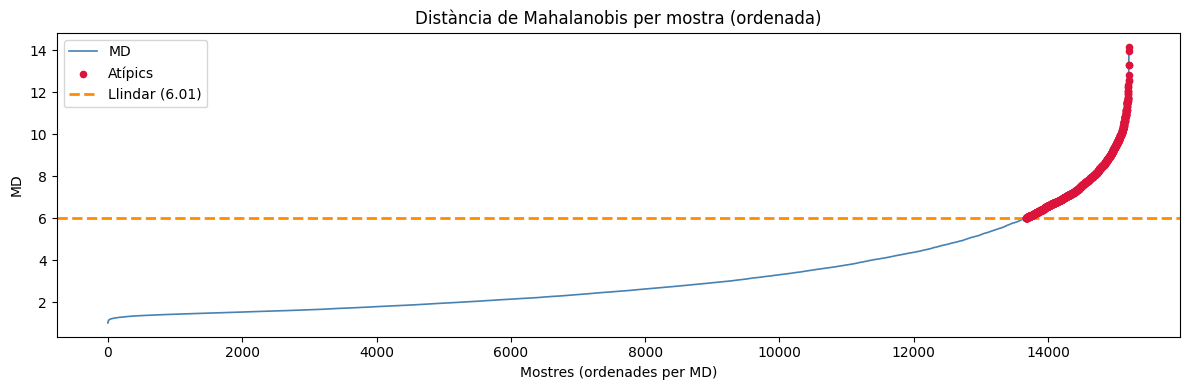

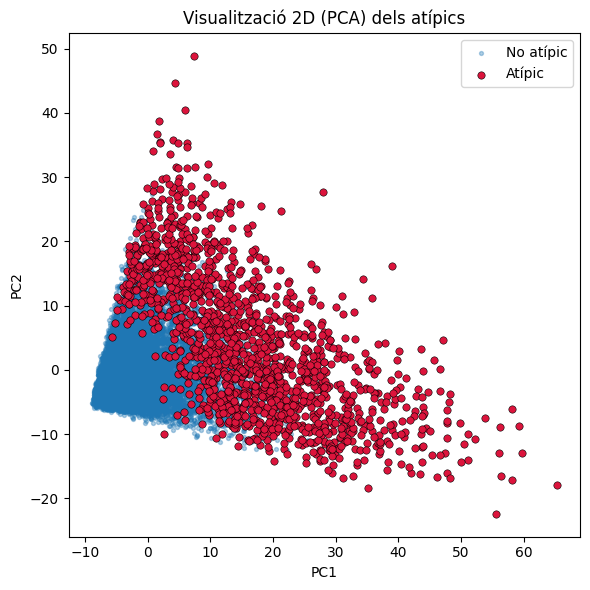

In [18]:
def mahalanobis_outliers(data, alpha=0.999):
    scaler = StandardScaler()
    data_scaled = scaler.fit_transform(data)

    pca_m = PCA(n_components=0.95, random_state=42)
    data_pca = pca_m.fit_transform(data_scaled)

    mean = np.mean(data_pca, axis=0)
    cov = np.cov(data_pca, rowvar=False)
    inv_cov = np.linalg.pinv(cov)

    diff = data_pca - mean
    md2 = np.einsum("ij,jk,ik->i", diff, inv_cov, diff)
    md = np.sqrt(np.clip(md2, 0, None))

    threshold = np.sqrt(chi2.ppf(alpha, df=data_pca.shape[1]))
    return md, md > threshold, threshold, data_pca


md_values, is_outlier, md_threshold, data_pca = mahalanobis_outliers(X)
print(f"Atipics detectats: {is_outlier.sum()} de {len(X)}; ({is_outlier.mean() * 100:.2f}%)")
print("Nota: no els eliminem en aquesta versió.")

# --- Plot 1: distància de Mahalanobis ordenada ---
order = np.argsort(md_values)
md_sorted = md_values[order]
out_sorted = is_outlier[order]

plt.figure(figsize=(12, 4))
plt.plot(md_sorted, color="steelblue", lw=1.2, label="MD")
plt.scatter(
    np.where(out_sorted)[0],
    md_sorted[out_sorted],
    color="crimson",
    s=20,
    label="Atípics",
    zorder=3,
)
plt.axhline(md_threshold, color="darkorange", ls="--", lw=2, label=f"Llindar ({md_threshold:.2f})")
plt.title("Distància de Mahalanobis per mostra (ordenada)")
plt.xlabel("Mostres (ordenades per MD)")
plt.ylabel("MD")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "distancia_mahalanobis_ordenada.png", dpi=300, bbox_inches="tight")
plt.show()

# --- Plot 2: projecció PCA 2D amb atípics ---
plt.figure(figsize=(6, 6))
plt.scatter(
    data_pca[~is_outlier, 0],
    data_pca[~is_outlier, 1],
    s=8,
    alpha=0.35,
    label="No atípic",
)
plt.scatter(
    data_pca[is_outlier, 0],
    data_pca[is_outlier, 1],
    s=28,
    c="crimson",
    edgecolors="k",
    linewidths=0.4,
    label="Atípic",
)
plt.title("Visualització 2D (PCA) dels atípics")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "visualitzacio_pca_2d_atipics.png", dpi=300, bbox_inches="tight")
plt.show()

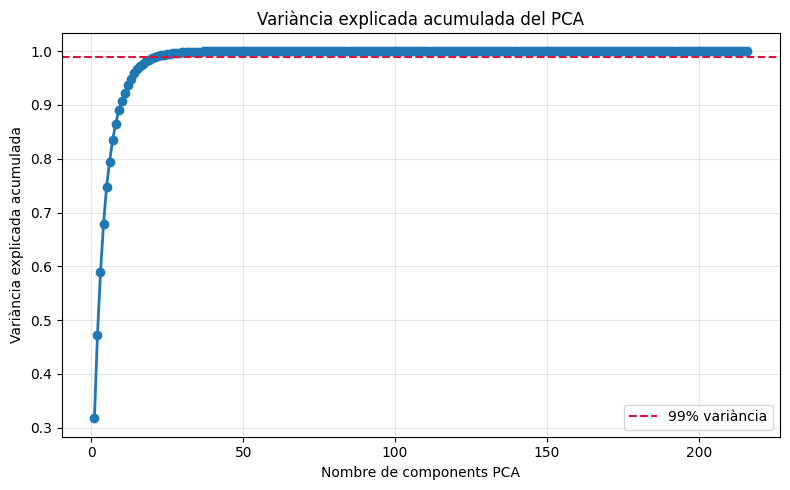

Components per 70% variància: 5
Components per 80% variància: 7
Components per 90% variància: 10
Components per 95% variància: 14
Components per 99% variància: 22
Components per 99.9% variància: 34


In [20]:
X_pca_source = X.copy()

X_scaled = StandardScaler().fit_transform(X_pca_source)
pca_full = PCA().fit(X_scaled)

cum_var = np.cumsum(pca_full.explained_variance_ratio_)
n_components = np.arange(1, len(cum_var) + 1)

plt.figure(figsize=(8, 5))
plt.plot(n_components, cum_var, marker="o", lw=2)
plt.axhline(0.99, color="crimson", ls="--", lw=1.5, label="99% variància")
plt.xlabel("Nombre de components PCA")
plt.ylabel("Variància explicada acumulada")
plt.title("Variància explicada acumulada del PCA")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "variancia_explicada_acumulada_pca.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"Components per 70% variància: {np.searchsorted(cum_var, 0.70) + 1}")
print(f"Components per 80% variància: {np.searchsorted(cum_var, 0.80) + 1}")
print(f"Components per 90% variància: {np.searchsorted(cum_var, 0.90) + 1}")
print(f"Components per 95% variància: {np.searchsorted(cum_var, 0.95) + 1}")
print(f"Components per 99% variància: {np.searchsorted(cum_var, 0.99) + 1}")
print(f"Components per 99.9% variància: {np.searchsorted(cum_var, 0.999) + 1}")

## Modelatge per subjecte

L'anàlisi es fa subjecte a subjecte. Per a cada individu s'aplica undersampling dins del mateix subjecte i després es fa validació creuada amb diversos models base per comparar famílies de classificadors.

L'objectiu és reportar l'accuracy i el F1 macro mitjans entre tots els subjectes per a cada família de model.

In [ ]:
import sys
from pathlib import Path

# Add src directory to path so we can import br_analysis
src_path = Path(r"c:\Users\nils\Documents\Universitat\TFG\src")
if str(src_path) not in sys.path:
    sys.path.insert(0, str(src_path))

from br_analysis.experiments import temporal_stratified_splits

SUBJECT_MODEL_SPECS = {
    "LR": {
        "factory": lambda: LogisticRegression(class_weight="balanced", max_iter=2000, random_state=42),
    },
    "LDA": {
        "factory": lambda: LDA(priors=[0.5, 0.5], solver="svd"),
    },
    "RF": {
        "factory": lambda: RandomForestClassifier(
            n_estimators=200,
            max_depth=16,
            min_samples_leaf=3,
            class_weight="balanced_subsample",
            random_state=42,
            n_jobs=-1,
        ),
    },
    "XGB": {
        "factory": lambda: XGBClassifier(
            n_estimators=220,
            max_depth=5,
            learning_rate=0.05,
            subsample=0.9,
            colsample_bytree=0.8,
            reg_lambda=1.0,
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1,
        ),
    },
    "LGBM": {
        "factory": lambda: LGBMClassifier(
            n_estimators=260,
            learning_rate=0.05,
            num_leaves=31,
            max_depth=-1,
            subsample=0.9,
            colsample_bytree=0.8,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1,
            verbose=-1,
        ),
    },
}


def build_subject_pipeline(model_name):
    spec = SUBJECT_MODEL_SPECS[model_name]
    return Pipeline(
        [
            ("log1p", FunctionTransformer(np.log1p, validate=False)),
            ("scaler", StandardScaler()),
            ("pca", PCA(n_components=0.99, random_state=42)),
            ("model", spec["factory"]()),
        ]
    )


def undersample_chronological(X_s, y_s, seed=42):
    n_min = min(int((y_s == 0).sum()), int((y_s == 1).sum()))
    idx_0 = np.where(y_s == 0)[0]
    idx_1 = np.where(y_s == 1)[0]
    rng = np.random.default_rng(seed)
    keep_idx = np.concatenate([rng.choice(idx_0, n_min, replace=False), rng.choice(idx_1, n_min, replace=False)])
    keep_idx.sort()  # Mantenim ordre temporal original
    return X_s[keep_idx], y_s[keep_idx]


subject_ids = np.unique(subj_list)
subject_rows = []
subject_model_rows = []

print("Configuració subjecte a subjecte (amb CV temporal i submostreig cronològic):")
print(f"Models: {', '.join(SUBJECT_MODEL_SPECS.keys())}")
print(f"Subjectes totals: {len(subject_ids)}")

for subj in subject_ids:
    subj_idx = np.where(subj_list == subj)[0]
    X_subj = X[subj_idx]
    y_subj = y[subj_idx]

    # Submostreig mantenint l'ordre cronològic de les dades d'EEG
    X_subj_bal, y_subj_bal = undersample_chronological(X_subj, y_subj, seed=42)
    class_counts = np.bincount(y_subj_bal, minlength=2)
    min_class = int(class_counts[class_counts > 0].min())
    n_splits_subj = min(5, min_class)

    if n_splits_subj < 2:
        print(f"{subj}: s'omet per falta de mostres a una classe ({class_counts.tolist()}).")
        continue

    try:
        # Validació creuada cronològica / temporal (sense barrejar, respecta ordre real)
        subj_cv = temporal_stratified_splits(y_subj_bal, n_splits_subj)
    except ValueError as e:
        print(f"{subj}: s'omet en no poder construir splits temporals vàlids ({e})")
        continue

    print(f"\n{subj} | raw={len(y_subj)} | balanced={len(y_subj_bal)} | C={class_counts[0]} | IP={class_counts[1]}")

    for model_name in SUBJECT_MODEL_SPECS:
        subj_pipeline = build_subject_pipeline(model_name)
        subj_results = cross_validate(
            subj_pipeline,
            X_subj_bal,
            y_subj_bal,
            cv=subj_cv,
            scoring={"accuracy": "accuracy", "f1_macro": "f1_macro"},
            n_jobs=-1,
        )

        row = {
            "subject": subj,
            "model": model_name,
            "n_samples_raw": int(len(y_subj)),
            "n_samples_bal": int(len(y_subj_bal)),
            "n_c": int((y_subj_bal == 0).sum()),
            "n_i": int((y_subj_bal == 1).sum()),
            "acc_mean": float(np.mean(subj_results["test_accuracy"])),
            "acc_std": float(np.std(subj_results["test_accuracy"])),
            "f1_mean": float(np.mean(subj_results["test_f1_macro"])),
            "f1_std": float(np.std(subj_results["test_f1_macro"])),
        }
        subject_model_rows.append(row)

        print(
            f"  {model_name:>4} | ACC={row['acc_mean']:.3f}±{row['acc_std']:.3f} | "
            f"F1={row['f1_mean']:.3f}±{row['f1_std']:.3f}"
        )

    best_subj = sorted(
        [r for r in subject_model_rows if r["subject"] == subj],
        key=lambda r: (r["f1_mean"], r["acc_mean"]),
        reverse=True,
    )[0]
    subject_rows.append(best_subj)

subject_acc_mean = float(np.mean([r["acc_mean"] for r in subject_rows]))
subject_acc_std = float(np.std([r["acc_mean"] for r in subject_rows]))
subject_f1_mean = float(np.mean([r["f1_mean"] for r in subject_rows]))
subject_f1_std = float(np.std([r["f1_mean"] for r in subject_rows]))

df_subject_results = pd.DataFrame(subject_rows).sort_values(["subject", "model"]).reset_index(drop=True)
df_model_results = pd.DataFrame(subject_model_rows).sort_values(["subject", "model"]).reset_index(drop=True)
df_subject_results.to_csv(TABLES_DIR / "subject_best_models.csv", index=False)
df_model_results.to_csv(TABLES_DIR / "subject_model_scores.csv", index=False)

print(f"Desat taula: {TABLES_DIR / 'subject_best_models.csv'}")
print(f"Desat taula: {TABLES_DIR / 'subject_model_scores.csv'}")
print("\nResum global subjecte a subjecte (millor model per subjecte):")
print(f"Accuracy mitjana entre subjectes: {subject_acc_mean:.3f} ± {subject_acc_std:.3f}")
print(f"F1 macro mitjà entre subjectes: {subject_f1_mean:.3f} ± {subject_f1_std:.3f}")
print(f"Subjectes avaluats: {len(subject_rows)}")

Configuració subjecte a subjecte (amb CV temporal i submostreig cronològic):
Models: LR, LDA, RF, XGB, LGBM
Subjectes totals: 47

P002 | raw=226 | balanced=226 | C=113 | IP=113
    LR | ACC=0.500±0.067 | F1=0.491±0.065
   LDA | ACC=0.515±0.074 | F1=0.504±0.074
    RF | ACC=0.511±0.047 | F1=0.496±0.037
   XGB | ACC=0.511±0.047 | F1=0.499±0.041
  LGBM | ACC=0.474±0.054 | F1=0.429±0.059

P003 | raw=144 | balanced=144 | C=72 | IP=72
    LR | ACC=0.567±0.094 | F1=0.552±0.098
   LDA | ACC=0.525±0.107 | F1=0.518±0.108
    RF | ACC=0.483±0.073 | F1=0.466±0.082
   XGB | ACC=0.467±0.072 | F1=0.451±0.077
  LGBM | ACC=0.517±0.073 | F1=0.480±0.109

P004 | raw=428 | balanced=428 | C=214 | IP=214
    LR | ACC=0.534±0.042 | F1=0.529±0.041
   LDA | ACC=0.534±0.040 | F1=0.530±0.038
    RF | ACC=0.517±0.077 | F1=0.505±0.071
   XGB | ACC=0.519±0.085 | F1=0.510±0.080
  LGBM | ACC=0.489±0.090 | F1=0.479±0.086

P005 | raw=306 | balanced=306 | C=153 | IP=153
    LR | ACC=0.529±0.074 | F1=0.528±0.073
   LDA | 

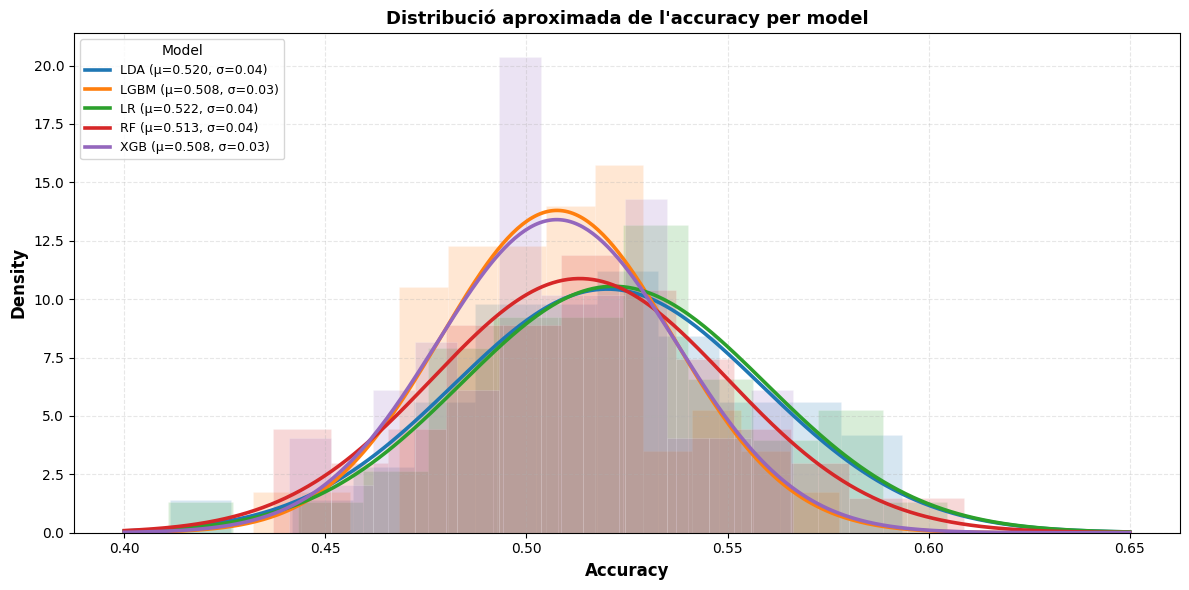

In [40]:
models = sorted(df_model_results["model"].unique())
cmap = plt.get_cmap("tab10")
colors = [cmap(i) for i in range(len(models))]

plt.figure(figsize=(12, 6))
ax = plt.gca()

# Common x-range for smooth Gaussian approximations
all_accs = df_model_results["acc_mean"].dropna().values
x_min, x_max = 0.4, 0.65
x_grid = np.linspace(x_min, x_max, 400)

for i, model in enumerate(models):
    accs = df_model_results.loc[df_model_results["model"] == model, "acc_mean"].dropna().values
    if len(accs) == 0:
        continue

    color = colors[i % len(colors)]
    mu = float(accs.mean())
    sigma = float(accs.std(ddof=1)) if len(accs) > 1 else 0.0
    sigma = max(sigma, 1e-3)

    # Histogram kept light in the background; Gaussian curve carries the shape.
    ax.hist(
        accs,
        bins=12,
        density=True,
        alpha=0.18,
        color=color,
        edgecolor="white",
        linewidth=0.6,
    )
    ax.plot(
        x_grid,
        norm.pdf(x_grid, mu, sigma),
        color=color,
        lw=2.6,
        label=f"{model} (μ={mu:.3f}, σ={sigma:.2f})",
    )

ax.set_xlabel("Accuracy", fontsize=12, fontweight="bold")
ax.set_ylabel("Density", fontsize=12, fontweight="bold")
ax.set_title("Distribució aproximada de l'accuracy per model", fontsize=13, fontweight="bold")
ax.legend(loc="upper left", fontsize=9, frameon=True, title="Model")
ax.grid(alpha=0.3, linestyle="--")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "acc_histograms_models.png", dpi=300, bbox_inches="tight")
plt.show()